In [1]:
from config import *
import Minimal_Model_1D as mm1D
import Minimal_Model_2D as mm2D
import Operators2D as O2d

In [2]:
def Correlation_2D(A, n, ax, ay, i, j, dl=1):

    """
        Returns correlation function between point labelled by i, j on a n X m lattice
        
        Args:
            A (float) : normalizing ocnstant for correlation function
            i, j (int) : index of two poins between which correlation function needs to be calculated
            dl (float) : decay length of correlation function 
        
    """

    x_dis = ((i%n) - (j%n))*ax   ## x distance between two points on lattice with index i,j labelled in graph way 

    y_dis = ((i//n) - (j//n))*ay   ## y distance between two points on lattice with index i,j labelled in graph way 

    return A**2 * math.exp(-abs(math.sqrt(x_dis**2 + y_dis**2))/dl)

def variance_of_equivalent_uncorrelated_disorder(WV, A, n, m, ax, ay, dl=1):

    """
        Returns equivalent <VV> or variance for uncorrelated disorder in 2D given correlated disorder magnitude A   
        
        Args:
            WV (array) : Array of dim (2X2XnXm, 1) representing wavefunction 
            A (float) : normalizing ocnstant for correlation function
            dl (float) : decay length of correlation function 
        
    """
 
    WVb = WV.reshape(2,2,m*n)           ### reshaping one D wavevector for ease of summing with the correlation function which relies on i,j being latice index

    var_corr = 0                        ### intializing variance of uncorrelated disorder

    #for k in range(2):

        #for l in range(2):

    for i in range(m*n):

        for j in range(m*n):

            var_corr += abs(WVb[0,0,i])**2*abs(WVb[0,0,j])**2*Correlation_2D(A, n, ax, ay, i, j, dl)*ax**2*ay**2 ### summing square of given wavefunction with correlation function to find corr_var

    var_uncorr = var_corr/np.sum(np.abs(WVb[0,0,:])**4)/ax/ay      ### Finding corr var using uncorr var 

    return var_uncorr, var_corr

def QW_wf(n,i,a):

    return math.sqrt(2/(n-1))*np.sin(i*np.pi*np.arange(n)/(n-1))

def QW_wf_2d(n, m, i, ax, ay):

    V = np.empty((m*n,1))

    for i in range(m):

        for j in range(n):

            V[i*n+j] = math.sqrt(2/(n-1))*math.sqrt(2/(m-1))*math.sin(j*math.pi/(n-1))*math.sin(i*math.pi/(m-1))

    return V 



In [3]:
sum = 0 

for i in range(100):

    for j in range(100):

        sum += Correlation_2D(1,10,1,1,i,j,1)


print(sum*4)

2036.4138054684597


In [4]:
np.sum(np.ones(100))

100.0

In [5]:
2036/400

5.09

In [6]:
WV = np.tile(np.ones(100),4)

print(variance_of_equivalent_uncorrelated_disorder(WV, 1, 10, 10, 1, 1, 1))

(5.09103451367115, 509.1034513671149)


In [7]:
#### checking wrt different lattice constant
#### corr var should remain same, only the uncorr var should change
#### Also, uncorr var should more or less remain same irrespective of length of the sample

N = 40
AX = 0.25

M = 40
AY = 0.25

I = 1

WV = np.tile(QW_wf_2d(N,M,I,AX,AY),4)

print(np.sum(np.abs(QW_wf_2d(N,M,I,AX,AY))**2))

print(variance_of_equivalent_uncorrelated_disorder(WV, 1,N,M,AX,AY,1))

a, b = variance_of_equivalent_uncorrelated_disorder(WV, 1,N,M,AX,AY,1)

print(b/a)

print(b)



0.9999999999999999
(2.6891423557420007, 3.328556664781072e-05)
1.2377762961019002e-05
3.328556664781072e-05


In [8]:

N = 20
AX = 0.5

M = 20
AY = 0.5

I = 1

WV = np.tile(QW_wf_2d(N,M,I,AX,AY),4)

print(np.sum(np.abs(WV)**2))

print(variance_of_equivalent_uncorrelated_disorder(WV, 1,N,M,AX,AY,1))

a, b = variance_of_equivalent_uncorrelated_disorder(WV, 1,N,M,AX,AY,1)

print(b/a)


4.000000000000001
(2.756232016259587, 0.0004954379997603106)
0.0001797519210420671


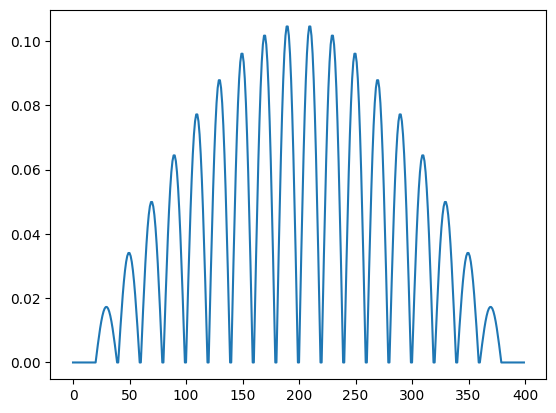

In [9]:
plt.plot(QW_wf_2d(N,M,I,AX,AY))

In [13]:

### changing ;attice constant in x direction 

N = 20
AX = 0.5

M = 5
AY = 1

I = 1

WV = np.tile(QW_wf_2d(N,M,I,AX,AY),4)

print(variance_of_equivalent_uncorrelated_disorder(WV, 1,N,M,AX,AY,2))



(20.054051600879813, 4813.040874542854)


In [12]:
#### checking wrt one d 

N = 200
AX = 1

M = 1
AY = 1

I = 1

WV = np.tile(QW_wf(N,I,AX),4)/2

print(np.sum(np.abs(WV)**2))

print(variance_of_equivalent_uncorrelated_disorder(WV, 1,N,M,AX,AY,0.01))

a, b = variance_of_equivalent_uncorrelated_disorder(WV, 1,N,M,AX,AY,1)

print(b/a)

#print(b/4*AX*AY*(N-1)*(M-1))

1.0
(1.0000000000000004, 0.0018844221105527646)
0.0018844221105527637
